In [18]:
from langchain_community.document_loaders import PyPDFLoader
import os

documents = []

book_files = {
    "Physics": "books/physics2.pdf",
    "Chemistry": "books/chemistry1.pdf"
}

for subject, file_path in book_files.items():

    loader = PyPDFLoader(file_path)

    docs = loader.load()

    for doc in docs:

        doc.metadata["subject"] = subject

    documents.extend(docs)

print(f"Total Pages = {len(documents)}")

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/ULTGAD+Bookman-Demi', '/Encoding': '/WinAnsiEncoding', '/FirstChar': 32, '/FontDescriptor': IndirectObject(12, 0, 2396431776336), '/LastChar': 150, '/Subtype': '/Type1', '/Type': '/Font', '/Widths': [340, 0, 0, 0, 0, 0, 0, 0, 320, 320, 0, 0, 340, 360, 340, 0, 660, 660, 660, 660, 660, 660, 660, 660, 660, 660, 340, 0, 0, 0, 0, 0, 0, 720, 720, 740, 780, 720, 680, 780, 820, 400, 0, 800, 640, 940, 740, 800, 660, 0, 780, 660, 700, 740, 720, 940, 780, 700, 0, 0, 0, 0, 0, 0, 0, 580, 600, 580, 640, 580, 380, 580, 680, 360, 0, 0, 340, 1000, 680, 620, 640, 0, 460, 520, 460, 660, 600, 0, 0, 620, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 500]}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/BHTWTE+Bookman-Light

Total Pages = 32


In [19]:
def clean_text(text):

    text = text.replace("\n", " ")

    text = " ".join(text.split())

    return text


for doc in documents:

    doc.page_content = clean_text(
        doc.page_content
    )

print("Cleaning Completed")

Cleaning Completed


In [20]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

chunks = splitter.split_documents(
    documents
)

print(f"Total Chunks = {len(chunks)}")

Total Chunks = 62


In [21]:
from langchain_ollama import OllamaEmbeddings

embedding_model = OllamaEmbeddings(
    model="nomic-embed-text"
)

print("Embedding Model Ready")

Embedding Model Ready


In [22]:
from langchain_community.vectorstores import FAISS

vector_store = FAISS.from_documents(
    chunks,
    embedding_model
)

vector_store.save_local(
    "faiss_12th_std"
)

print("FAISS Created")

FAISS Created


In [24]:
physics_retriever = vector_store.as_retriever(
    search_kwargs={
        "k":5,
        "filter":{
            "subject":"Physics"
        }
    }
)

chemistry_retriever = vector_store.as_retriever(
    search_kwargs={
        "k":5,
        "filter":{
            "subject":"Chemistry"
        }
    }
)

maths_retriever = vector_store.as_retriever(
    search_kwargs={
        "k":5,
        "filter":{
            "subject":"Mathematics"
        }
    }
)


In [26]:
from langchain_ollama import ChatOllama

model = ChatOllama(
    model="llama3.2:latest"
)

print("LLM Ready")

LLM Ready


In [27]:
import time

def retry_node(retries=3):

    def decorator(func):

        def wrapper(state):

            for attempt in range(retries):

                try:

                    return func(state)

                except Exception as e:

                    print(
                        f"{func.__name__} Retry {attempt+1}"
                    )

                    state["error"] = str(e)

                    time.sleep(2)

            state["status"] = "failed"

            return state

        return wrapper

    return decorator

In [28]:
@retry_node()
def classify_subject_node(state):

    prompt = f"""
    Classify the question into:

    Physics
    Chemistry
    Mathematics

    Question:
    {state['question']}

    Return only subject.
    """

    response = model.invoke(prompt)

    state["subject"] = response.content.strip()

    return state

In [29]:
@retry_node()
def retrieve_documents_node(state):

    subject = state["subject"]

    if subject == "Physics":

        docs = physics_retriever.invoke(
            state["question"]
        )

    elif subject == "Chemistry":

        docs = chemistry_retriever.invoke(
            state["question"]
        )

    else:

        docs = maths_retriever.invoke(
            state["question"]
        )

    state["documents"] = docs

    return state

In [30]:
@retry_node()
def build_context_node(state):

    context = "\n\n".join(

        doc.page_content

        for doc in state["documents"]
    )

    state["context"] = context

    return state

In [31]:
@retry_node()
def generate_answer_node(state):

    prompt = f"""
    You are an expert class 12 tutor.

    Subject:
    {state['subject']}

    Context:
    {state['context']}

    Question:
    {state['question']}

    Answer using only context.
    """

    response = model.invoke(prompt)

    state["answer"] = response.content

    return state

In [34]:
def failure_node(state):

    state["answer"] = \
        "Sorry, unable to answer."

    return state

In [35]:
from typing import TypedDict
from langchain_core.documents import Document

class StudentState(TypedDict):

    question: str

    subject: str

    documents: list[Document]

    context: str

    answer: str

    retry_count: int

    status: str

    error: str

In [36]:
from langgraph.graph import (
    StateGraph,
    START,
    END
)

builder = StateGraph(
    StudentState
)

builder.add_node(
    "classify",
    classify_subject_node
)

builder.add_node(
    "retrieve",
    retrieve_documents_node
)

builder.add_node(
    "context",
    build_context_node
)

builder.add_node(
    "answer",
    generate_answer_node
)

builder.add_node(
    "failure",
    failure_node
)

In [37]:
builder.add_edge(
    START,
    "classify"
)

builder.add_edge(
    "classify",
    "retrieve"
)

builder.add_edge(
    "retrieve",
    "context"
)

builder.add_edge(
    "context",
    "answer"
)

builder.add_edge(
    "answer",
    END
)

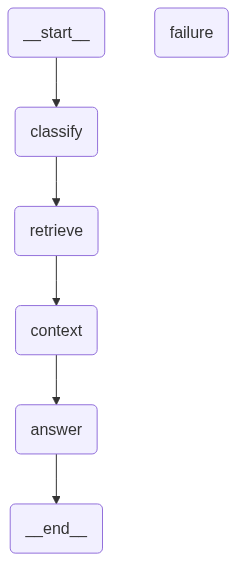

In [38]:
student_graph = builder.compile()

student_graph

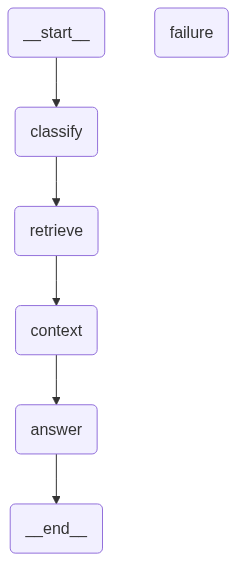

In [39]:
from IPython.display import Image

Image(
    student_graph
    .get_graph()
    .draw_mermaid_png()
)

In [40]:
response = student_graph.invoke(
    {
        "question":
        "State Gauss Law",

        "subject":"",

        "documents":[],

        "context":"",

        "answer":"",

        "retry_count":0,

        "status":"",

        "error":""
    }
)

print(
    response["answer"]
)

Gauss Law states that the total electric flux through a closed surface is proportional to the charge enclosed within that surface.
